## The Machine Learning Workflow

### Get the Data

- Import aller relevanten Module
- Laden der Daten aus der CSV-Datei

In [1]:
# Import aller relevanten Module
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.model_selection import cross_val_predict
from sklearn.inspection import permutation_importance
import joblib
from sklearn.metrics import (
    RocCurveDisplay,
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)

RANDOM_STATE = 42

In [2]:
# Laden der Daten aus der CSV-Datei
df = pd.read_csv("./data/ks-projects-201801.csv")

### First Look at the Data

- erste allgemeine Informationen über die Daten sammeln/ergründen

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 378661 entries, 0 to 378660
Data columns (total 15 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   ID                378661 non-null  int64  
 1   name              378657 non-null  str    
 2   category          378661 non-null  str    
 3   main_category     378661 non-null  str    
 4   currency          378661 non-null  str    
 5   deadline          378661 non-null  str    
 6   goal              378661 non-null  float64
 7   launched          378661 non-null  str    
 8   pledged           378661 non-null  float64
 9   state             378661 non-null  str    
 10  backers           378661 non-null  int64  
 11  country           378661 non-null  str    
 12  usd pledged       374864 non-null  float64
 13  usd_pledged_real  378661 non-null  float64
 14  usd_goal_real     378661 non-null  float64
dtypes: float64(5), int64(2), str(8)
memory usage: 43.3 MB


In [4]:
df.columns

Index(['ID', 'name', 'category', 'main_category', 'currency', 'deadline',
       'goal', 'launched', 'pledged', 'state', 'backers', 'country',
       'usd pledged', 'usd_pledged_real', 'usd_goal_real'],
      dtype='str')

In [5]:
df["state"].value_counts()

state
failed        197719
successful    133956
canceled       38779
undefined       3562
live            2799
suspended       1846
Name: count, dtype: int64

## Clean the Data

- Umwandeln der Datumsangaben in das DateTime-Format
- Entfernen aller unnötigen Stati aus der Spalte "state", bis nur noch "successful" und "failed" übrig bleiben. Im Anschluss werden beide Werte in 0 und 1 umgeandelt, damit die Modelle damit weiter rechnen können
- Entfernen der Spalten die erst zum Abschluss des jeweiligen Projekts bekannt sein können (so wird Data Leakage verhindert). Des Weiteren werden auch die Spalten entfernt, die für die Berechnungen der Modelle irrelevant sind oder doppelt vorhanden sind
- Befüllen der Namensspalte bei Projekten die ohne Namen eingetragen sind. Weiterhin werden fehlerhafte Ländercodes umbenannt. Zum Schluss werden Projekte mit einem zu geringen Finanzierungsziel entfernt (fehlerhafte Einträge)
- Zum Abschluss eine Überprüfung auf Duplikate

In [6]:
# Umwandeln der Datumsangaben in das DateTime-Format
df["launched"] = pd.to_datetime(df["launched"])
df["deadline"] = pd.to_datetime(df["deadline"])

In [7]:
# Entfernen aller unnötigen Stati aus der Spalte "state", bis nur noch "successful" und "failed" übrig bleiben
df = df[df["state"].isin(["successful", "failed"])].copy()

# Im Anschluss werden beide Werte in 0 und 1 umgeandelt, damit die Modelle damit weiter rechnen können
df["success"] = (df["state"] == "successful").astype(int)

In [8]:
# Entfernen der Spalten die erst zum Abschluss des jeweiligen Projekts bekannt sein können (so wird Data Leakage verhindert) 
# Des Weiteren werden auch die Spalten entfernt, die für die Berechnungen der Modelle irrelevant sind oder doppelt vorhanden sind
leakage_cols = ["pledged", "usd pledged", "usd_pledged_real", "backers"]
unused_cols = ["ID", "goal", "state"]

df = df.drop(columns=leakage_cols + unused_cols)
df = df.rename(columns={"usd_goal_real": "goal_usd"})

In [9]:
# Befüllen der Namensspalte bei Projekten die ohne Namen eingetragen sind
df["name"] = df["name"].fillna("")

# Weiterhin werden fehlerhafte Ländercodes umbenannt
df["country"] = df["country"].replace('N,0"', "unknown")

# Zum Schluss werden Projekte mit einem zu geringen Finanzierungsziel entfernt (fehlerhafte Einträge)
df = df[df["goal_usd"] >= 1]

In [10]:
# Zum Abschluss eine Überprüfung auf Duplikate
print("Duplikate:", df.duplicated(["name", "launched"]).sum())

Duplikate: 0


## Train-Test Split

- Aufspalten der Daten in Traningsdaten und Testdaten. Validierungsdaten werden an dieser Stelle nicht separat abgespalten (es erfolgt eine spätere Cross-Validation auf den Traningsdaten)

In [11]:
X = df.drop(columns="success")
y = df["success"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

## Explore the Training Data

- (Erneutes) Zusammenfügen der Zielveriablendaten und der restlichen Daten (aus dem Trainingsdatensatz) zu einer einzigen Tabelle, damit die EDA durchgeführt werden kann
- Sammeln der allgemeinen Informationen über die Traningsdaten
- Balkendiagramm zur Visualisierung der Verteilung der Zielvariablen
- Boxplot und Histogramm zur Verteilung des Finanzierungsziels
- Balkendiagramm zur Erfolgsquote nach Höhe des Finanzierungsziels
- Balkendiagramm zur Erfolgsquote nach Hauptkategorie
- Balkendiagramm zur Erfolgsquote nach Kampagnendauer
- Liniendiegramm und Balkendiagramm zur Erfolgsquote nach Startjahr bzw. Startmonat
- Balkendiagramm zur Erfolgsquote der 10 häufigsten Länder
- Korrelation zwischen den numerischen Features und der Zielvariablen
- Visualisierung der Korrelation zwischen den numerischen Features und der Zielvariablen

In [12]:
# (Erneutes) Zusammenfügen der Zielveriablendaten und der restlichen Daten (aus dem Trainingsdatensatz) zu einer einzigen Tabelle, damit die EDA durchgeführt werden kann
train = X_train.assign(success=y_train)
train.head()

,name,category,main_category,currency,deadline,launched,country,goal_usd,success
187313,"Worm Quartet ""Songs Of The Maniacs"" Album",Indie Rock,Music,USD,2012-06-15,2012-05-18 02:53:16,US,1300.00,1
3354,Monster Documentary,Documentary,Film & Video,USD,2012-01-21,2011-11-22 03:43:31,US,5000.00,0
215718,"Support, Direction, Space: Embodying the Yoga ...",Nonfiction,Publishing,GBP,2016-07-19,2016-06-07 16:18:05,GB,15714.01,1
32997,MakersUnited! Value the Craft,Makerspaces,Technology,USD,2015-11-21,2015-10-17 18:02:59,US,15000.00,1
337671,STANDING EIGHT,Drama,Film & Video,USD,2015-04-01,2015-03-03 22:30:16,US,10500.00,1


In [13]:
# Sammeln der allgemeinen Informationen über die Traningsdaten
train.info()

<class 'pandas.DataFrame'>
Index: 265317 entries, 187313 to 24568
Data columns (total 9 columns):
 #   Column         Non-Null Count   Dtype         
---  ------         --------------   -----         
 0   name           265317 non-null  str           
 1   category       265317 non-null  str           
 2   main_category  265317 non-null  str           
 3   currency       265317 non-null  str           
 4   deadline       265317 non-null  datetime64[us]
 5   launched       265317 non-null  datetime64[us]
 6   country        265317 non-null  str           
 7   goal_usd       265317 non-null  float64       
 8   success        265317 non-null  int64         
dtypes: datetime64[us](2), float64(1), int64(1), str(5)
memory usage: 20.2 MB


In [14]:
train.nunique()

name             263932
category            159
main_category        15
currency             14
deadline           3095
launched         265050
country              23
goal_usd          38435
success               2
dtype: int64

In [15]:
train["goal_usd"].describe().round(0)

count       265317.0
mean         41433.0
std        1075635.0
min              1.0
25%           2000.0
50%           5000.0
75%          15000.0
max      151395870.0
Name: goal_usd, dtype: float64

success
0    0.596
1    0.404
Name: proportion, dtype: float64


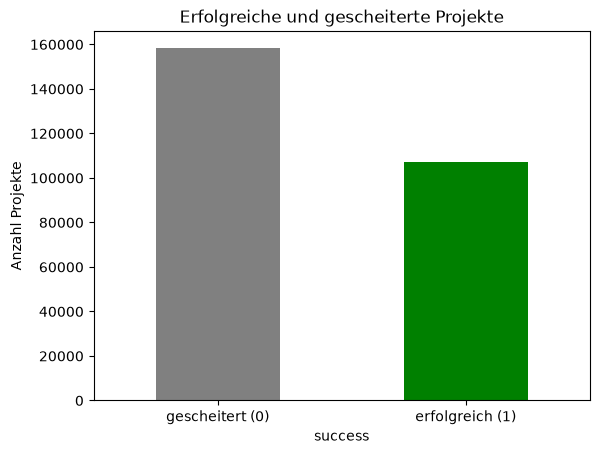

In [16]:
# Balkendiagramm zur Visualisierung der Verteilung der Zielvariablen
print(y_train.value_counts(normalize=True).round(3))

counts = y_train.value_counts().sort_index()
ax = counts.plot(kind="bar", color=["grey", "green"])
ax.set_xticklabels(["gescheitert (0)", "erfolgreich (1)"], rotation=0)
ax.set_ylabel("Anzahl Projekte")
ax.set_title("Erfolgreiche und gescheiterte Projekte")
plt.show()

/var/folders/17/kxb5ql9s3673yrwwl1ldtqvr0000gn/T/ipykernel_56673/918204413.py:4: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[0].boxplot(train["goal_usd"], vert=False)


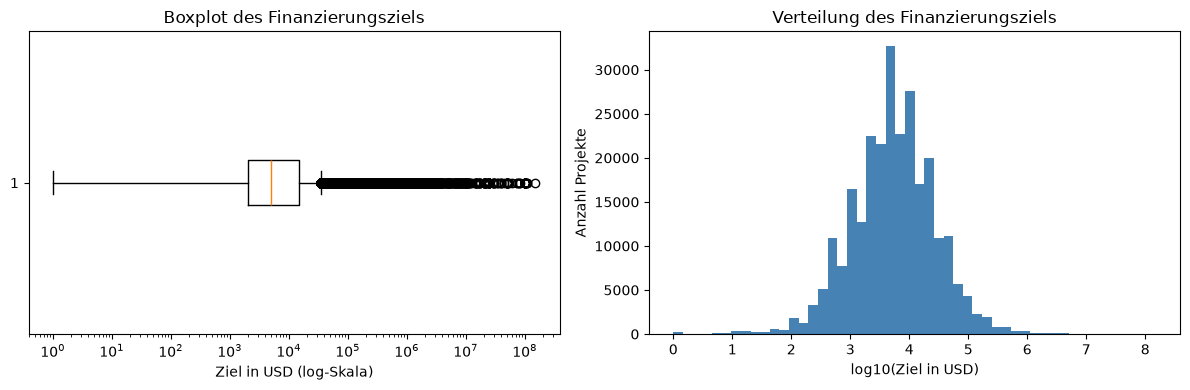

In [17]:
# Boxplot und Histogramm zur Verteilung des Finanzierungsziels
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].boxplot(train["goal_usd"], vert=False)
axes[0].set_xscale("log")
axes[0].set_xlabel("Ziel in USD (log-Skala)")
axes[0].set_title("Boxplot des Finanzierungsziels")

axes[1].hist(np.log10(train["goal_usd"]), bins=50, color="steelblue")
axes[1].set_xlabel("log10(Ziel in USD)")
axes[1].set_ylabel("Anzahl Projekte")
axes[1].set_title("Verteilung des Finanzierungsziels")

plt.tight_layout()
plt.show()

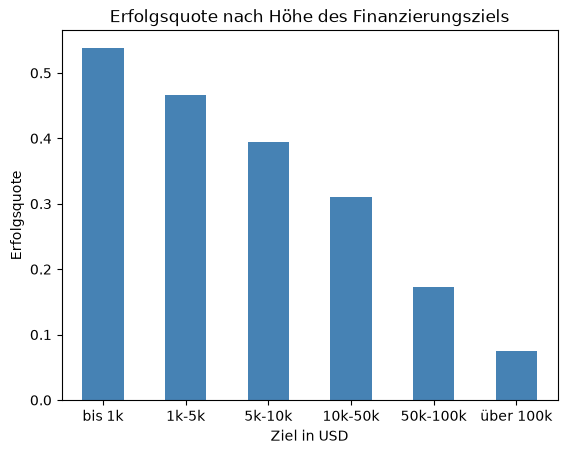

In [18]:
# Balkendiagramm zur Erfolgsquote nach Höhe des Finanzierungsziels
goal_bins = [0, 1_000, 5_000, 10_000, 50_000, 100_000, np.inf]
goal_labels = ["bis 1k", "1k-5k", "5k-10k", "10k-50k", "50k-100k", "über 100k"]
goal_group = pd.cut(train["goal_usd"], bins=goal_bins, labels=goal_labels)

rate_by_goal = train.groupby(goal_group, observed=True)["success"].mean()

ax = rate_by_goal.plot(kind="bar", color="steelblue")
ax.set_xlabel("Ziel in USD")
ax.set_ylabel("Erfolgsquote")
ax.set_title("Erfolgsquote nach Höhe des Finanzierungsziels")
plt.xticks(rotation=0)
plt.show()


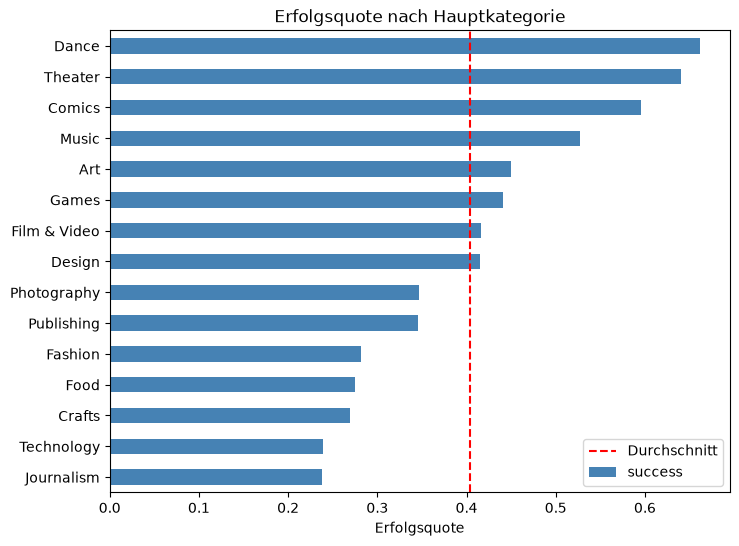

In [19]:
# Balkendiagramm zur Erfolgsquote nach Hauptkategorie
rate_by_category = (
    train.groupby("main_category")["success"].mean().sort_values()
)

ax = rate_by_category.plot(kind="barh", color="steelblue", figsize=(8, 6))
ax.axvline(y_train.mean(), color="red", linestyle="--", label="Durchschnitt")
ax.set_xlabel("Erfolgsquote")
ax.set_ylabel("")
ax.set_title("Erfolgsquote nach Hauptkategorie")
ax.legend()
plt.show()


count    265317.0
mean         33.9
std          12.7
min           1.0
25%          30.0
50%          30.0
75%          36.0
max          92.0
dtype: float64


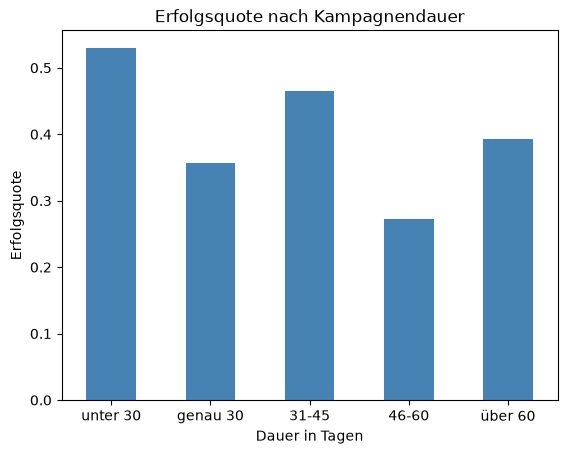

In [20]:
# Balkendiagramm zur Erfolgsquote nach Kampagnendauer
duration_days = (train["deadline"] - train["launched"].dt.normalize()).dt.days
print(duration_days.describe().round(1))

duration_bins = [0, 29, 30, 45, 60, 92]
duration_labels = ["unter 30", "genau 30", "31-45", "46-60", "über 60"]
duration_group = pd.cut(
    duration_days, bins=duration_bins, labels=duration_labels
)

rate_by_duration = (
    train.groupby(duration_group, observed=True)["success"].mean()
)

ax = rate_by_duration.plot(kind="bar", color="steelblue")
ax.set_xlabel("Dauer in Tagen")
ax.set_ylabel("Erfolgsquote")
ax.set_title("Erfolgsquote nach Kampagnendauer")
plt.xticks(rotation=0)
plt.show()

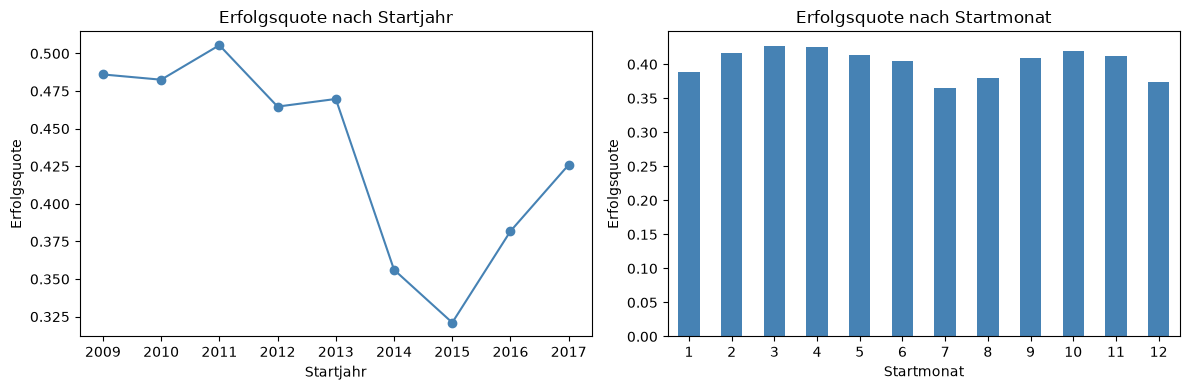

In [21]:
# Liniendiegramm und Balkendiagramm zur Erfolgsquote nach Startjahr bzw. Startmonat
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

rate_by_year = train.groupby(train["launched"].dt.year)["success"].mean()
rate_by_year.plot(ax=axes[0], marker="o", color="steelblue")
axes[0].set_xlabel("Startjahr")
axes[0].set_ylabel("Erfolgsquote")
axes[0].set_title("Erfolgsquote nach Startjahr")

rate_by_month = train.groupby(train["launched"].dt.month)["success"].mean()
rate_by_month.plot(ax=axes[1], kind="bar", color="steelblue")
axes[1].set_xlabel("Startmonat")
axes[1].set_ylabel("Erfolgsquote")
axes[1].set_title("Erfolgsquote nach Startmonat")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

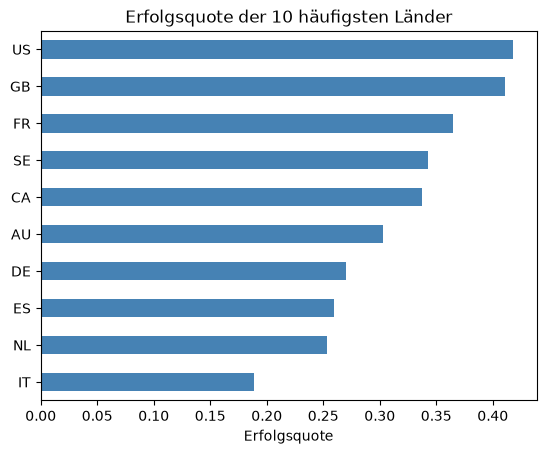

country
US    0.788
GB    0.089
CA    0.037
Name: proportion, dtype: float64


In [22]:
# Balkendiagramm zur Erfolgsquote der 10 häufigsten Länder
top_countries = train["country"].value_counts().head(10).index
rate_by_country = (
    train[train["country"].isin(top_countries)]
    .groupby("country")["success"]
    .mean()
    .sort_values()
)

ax = rate_by_country.plot(kind="barh", color="steelblue")
ax.set_xlabel("Erfolgsquote")
ax.set_ylabel("")
ax.set_title("Erfolgsquote der 10 häufigsten Länder")
plt.show()

print(train["country"].value_counts(normalize=True).head(3).round(3))

In [23]:
# Korrelation zwischen den numerischen Features und der Zielvariablen
numeric_view = pd.DataFrame({
    "log_goal": np.log10(train["goal_usd"]),
    "duration_days": duration_days,
    "name_length": train["name"].str.len(),
    "success": train["success"],
})

corr = numeric_view.corr().round(2)

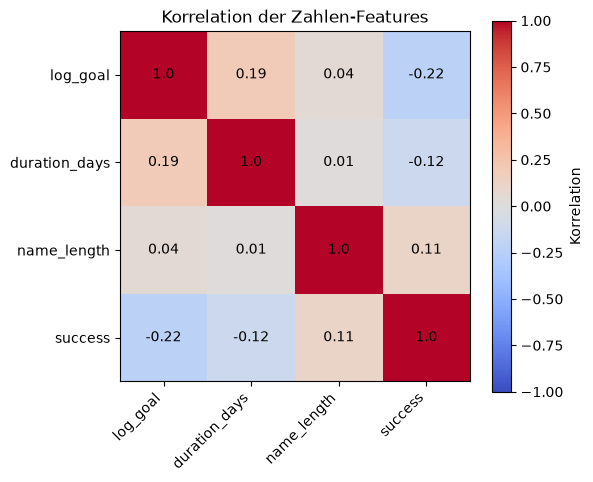

In [24]:
# Visualisierung der Korrelation zwischen den numerischen Features und der Zielvariablen
fig, ax = plt.subplots(figsize=(6, 5))

im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
fig.colorbar(im, ax=ax, label="Korrelation")

ax.set_xticks(range(len(corr.columns)))
ax.set_xticklabels(corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr.columns)))
ax.set_yticklabels(corr.columns)

for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, corr.iloc[i, j], ha="center", va="center")

ax.set_title("Korrelation der Zahlen-Features")
plt.tight_layout()
plt.show()

## Feature Engineering

- Erstellen einer Funktion für das Feature-Engineering
    - Log-Scaling des Finanzierungsziels
    - Berechnung der Kampagnendauer in Tagen
    - Erstellung von Features für Startjahr, Startmonat und Wochentag
    - Erstellung von Features für die Länge des Projektnamens und die Anzahl der Wörter im Projektnamen
- Definieren der numerischen und kategorischen Features für die Modellierung
 - Definieren der Cross-Validation und der Bewertungsmetriken

In [25]:
# Erstellen einer Funktion für das Feature-Engineering
def add_features(data):
    """Erstellt neue Features aus den Rohdaten."""
    data = data.copy()

    # Log-Scaling des Finanzierungsziels
    data["log_goal"] = np.log10(data["goal_usd"])

    # Berechnung der Kampagnendauer in Tagen
    data["duration_days"] = (
        data["deadline"] - data["launched"].dt.normalize()
    ).dt.days

    # Erstellung von Features für Startjahr, Startmonat und Wochentag
    data["launch_year"] = data["launched"].dt.year
    data["launch_month"] = data["launched"].dt.month
    data["launch_weekday"] = data["launched"].dt.day_of_week

    # Erstellung von Features für die Länge des Projektnamens und die Anzahl der Wörter im Projektnamen
    data["name_length"] = data["name"].str.len()
    data["name_words"] = data["name"].str.split().str.len().fillna(0)

    return data


X_train_feat = add_features(X_train)
X_train_feat.head()

,name,category,main_category,currency,deadline,launched,country,goal_usd,log_goal,duration_days,launch_year,launch_month,launch_weekday,name_length,name_words
187313,"Worm Quartet ""Songs Of The Maniacs"" Album",Indie Rock,Music,USD,2012-06-15,2012-05-18 02:53:16,US,1300.00,3.113943,28,2012,5,4,41,7
3354,Monster Documentary,Documentary,Film & Video,USD,2012-01-21,2011-11-22 03:43:31,US,5000.00,3.698970,60,2011,11,1,19,2
215718,"Support, Direction, Space: Embodying the Yoga ...",Nonfiction,Publishing,GBP,2016-07-19,2016-06-07 16:18:05,GB,15714.01,4.196287,42,2016,6,1,51,7
32997,MakersUnited! Value the Craft,Makerspaces,Technology,USD,2015-11-21,2015-10-17 18:02:59,US,15000.00,4.176091,35,2015,10,5,30,4
337671,STANDING EIGHT,Drama,Film & Video,USD,2015-04-01,2015-03-03 22:30:16,US,10500.00,4.021189,29,2015,3,1,14,2


In [26]:
# Definieren der numerischen und kategorischen Features für die Modellierung
num_features = [
    "log_goal",
    "duration_days",
    "launch_year",
    "launch_month",
    "launch_weekday",
    "name_length",
    "name_words",
]
cat_features = ["main_category", "category", "country"]

In [27]:
# Definieren der Cross-Validation und der Bewertungsmetriken
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = ["roc_auc", "accuracy", "f1", "precision", "recall"]

results = {}


def evaluate(name, model, X):
    """Bewertet ein Modell mit Cross-Validation und speichert das Ergebnis."""
    scores = cross_validate(
        model, X, y_train, cv=cv, scoring=scoring, n_jobs=-1
    )
    results[name] = {m: scores[f"test_{m}"].mean() for m in scoring}
    return pd.DataFrame(results).T.round(3)


def make_preprocessor(num_cols, cat_cols):
    """Skaliert Zahlen und wandelt Kategorien in 0/1-Spalten um."""
    return ColumnTransformer([
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ])

## Baseline Model

- Baseline-Modell: Dummy Classifier
- Baseline-Modell: Logistische Regression mit 2 Features

In [28]:
# Baseline-Modell: Dummy Classifier
dummy = DummyClassifier(strategy="most_frequent")
evaluate("Baseline: Dummy", dummy, X_train_feat)

/Users/aligokyer/ai_engineering/woche_08/ml-project/.venv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/aligokyer/ai_engineering/woche_08/ml-project/.venv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/aligokyer/ai_engineering/woche_08/ml-project/.venv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavio

,roc_auc,accuracy,f1,precision,recall
Baseline: Dummy,0.5,0.596,0.0,0.0,0.0


In [29]:
# Baseline-Modell: Logistische Regression mit 2 Features
baseline_logreg = Pipeline([
    ("prep", make_preprocessor(["log_goal"], ["main_category"])),
    ("model", LogisticRegression(max_iter=1000)),
])
evaluate("Baseline: LogReg (2 Features)", baseline_logreg, X_train_feat)

,roc_auc,accuracy,f1,precision,recall
Baseline: Dummy,0.500,0.596,0.000,0.000,0.00
Baseline: LogReg (2 Features),0.673,0.640,0.461,0.584,0.38


## Train the Model

- Erweitertes Modell: Logistische Regression mit allen Features
- Erweitertes Modell: Random Forest
- Erweitertes Modell: Extra Trees
- Hyperparameter-Tuning für Random Forest mit RandomizedSearchCV
- Bewertung des besten Random Forest Modells
- Balkendiagramm-Vergleich der Modelle anhand der ROC-AUC

In [30]:
# Erweitertes Modell: Logistische Regression mit allen Features
logreg = Pipeline([
    ("prep", make_preprocessor(num_features, cat_features)),
    ("model", LogisticRegression(max_iter=1000)),
])
evaluate("LogReg (alle Features)", logreg, X_train_feat)

,roc_auc,accuracy,f1,precision,recall
Baseline: Dummy,0.500,0.596,0.000,0.000,0.000
Baseline: LogReg (2 Features),0.673,0.640,0.461,0.584,0.380
LogReg (alle Features),0.729,0.676,0.552,0.626,0.494


In [31]:
# Erweitertes Modell: Random Forest
random_forest = Pipeline([
    ("prep", make_preprocessor(num_features, cat_features)),
    ("model", RandomForestClassifier(
        n_estimators=100,
        max_depth=15,
        min_samples_leaf=10,
        random_state=RANDOM_STATE,
    )),
])
evaluate("Random Forest", random_forest, X_train_feat)

,roc_auc,accuracy,f1,precision,recall
Baseline: Dummy,0.500,0.596,0.000,0.000,0.000
Baseline: LogReg (2 Features),0.673,0.640,0.461,0.584,0.380
LogReg (alle Features),0.729,0.676,0.552,0.626,0.494
Random Forest,0.733,0.673,0.474,0.675,0.366


In [32]:
# Erweitertes Modell: Extra Trees
extra_trees = Pipeline([
    ("prep", make_preprocessor(num_features, cat_features)),
    ("model", ExtraTreesClassifier(
        n_estimators=100,
        max_depth=15,
        min_samples_leaf=10,
        random_state=RANDOM_STATE,
    )),
])
evaluate("Extra Trees", extra_trees, X_train_feat)

,roc_auc,accuracy,f1,precision,recall
Baseline: Dummy,0.500,0.596,0.000,0.000,0.000
Baseline: LogReg (2 Features),0.673,0.640,0.461,0.584,0.380
LogReg (alle Features),0.729,0.676,0.552,0.626,0.494
Random Forest,0.733,0.673,0.474,0.675,0.366
Extra Trees,0.710,0.660,0.430,0.664,0.317


In [33]:
# Hyperparameter-Tuning für Random Forest mit RandomizedSearchCV
param_grid = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [10, 15, 20, 25],
    "model__min_samples_leaf": [5, 10, 20, 50],
    "model__max_features": ["sqrt", 0.3, 0.5],
}

search = RandomizedSearchCV(
    random_forest,
    param_distributions=param_grid,
    n_iter=8,
    scoring="roc_auc",
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE),
    random_state=RANDOM_STATE,
    n_jobs=-1,
)
search.fit(X_train_feat, y_train)

print("Beste Hyperparameter:", search.best_params_)
print("Beste ROC-AUC (CV):", round(search.best_score_, 3))

Beste Hyperparameter: {'model__n_estimators': 100, 'model__min_samples_leaf': 5, 'model__max_features': 0.3, 'model__max_depth': 25}
Beste ROC-AUC (CV): 0.75


In [34]:
# Bewertung des besten Random Forest Modells
best_random_forest = search.best_estimator_
evaluate("Random Forest (getunt)", best_random_forest, X_train_feat)

,roc_auc,accuracy,f1,precision,recall
Baseline: Dummy,0.500,0.596,0.000,0.000,0.000
Baseline: LogReg (2 Features),0.673,0.640,0.461,0.584,0.380
LogReg (alle Features),0.729,0.676,0.552,0.626,0.494
Random Forest,0.733,0.673,0.474,0.675,0.366
Extra Trees,0.710,0.660,0.430,0.664,0.317
Random Forest (getunt),0.751,0.693,0.579,0.648,0.523


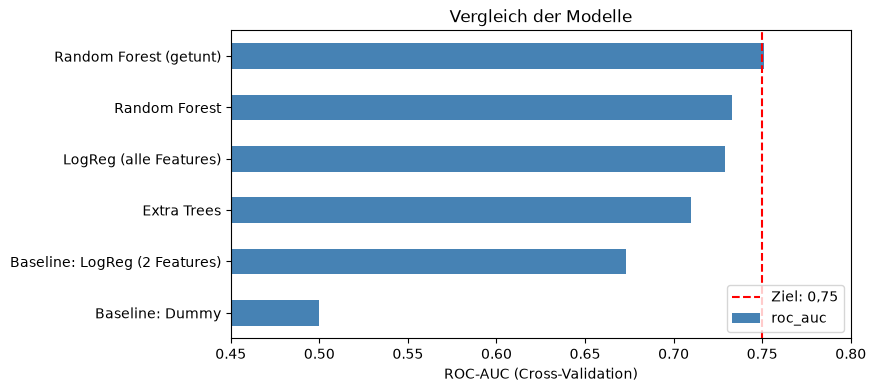

,roc_auc,accuracy,f1,precision,recall
Baseline: Dummy,0.500,0.596,0.000,0.000,0.000
Baseline: LogReg (2 Features),0.673,0.640,0.461,0.584,0.380
LogReg (alle Features),0.729,0.676,0.552,0.626,0.494
Random Forest,0.733,0.673,0.474,0.675,0.366
Extra Trees,0.710,0.660,0.430,0.664,0.317
Random Forest (getunt),0.751,0.693,0.579,0.648,0.523


In [35]:
# Balkendiagramm-Vergleich der Modelle anhand der ROC-AUC
results_table = pd.DataFrame(results).T.round(3)

ax = results_table["roc_auc"].sort_values().plot(
    kind="barh", color="steelblue", figsize=(8, 4)
)
ax.axvline(0.75, color="red", linestyle="--", label="Ziel: 0,75")
ax.set_xlabel("ROC-AUC (Cross-Validation)")
ax.set_ylabel("")
ax.set_title("Vergleich der Modelle")
ax.set_xlim(0.45, 0.8)
ax.legend(loc="lower right")
plt.show()

results_table

## Error Analysis

- Fehleraten und Konfusionsmatrix für das beste Random Forest Modell
- Visualisierung der vorhergesagten Erfolgswahrscheinlichkeiten für gescheiterte und erfolgreiche Projekte
- Visualisierung der Fehlerquote nach Kategorie und Höhe des Finanzierungsziels

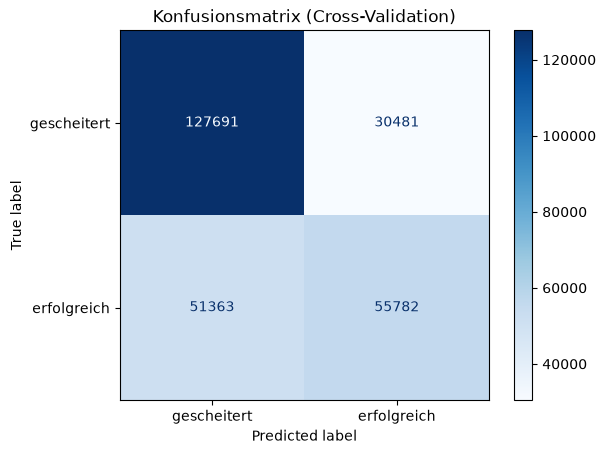

In [36]:
# Fehleraten und Konfusionsmatrix für das beste Random Forest Modell
proba_cv = cross_val_predict(
    best_random_forest,
    X_train_feat,
    y_train,
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE),
    method="predict_proba",
    n_jobs=-1,
)[:, 1]
pred_cv = (proba_cv >= 0.5).astype(int)

ConfusionMatrixDisplay.from_predictions(
    y_train,
    pred_cv,
    display_labels=["gescheitert", "erfolgreich"],
    cmap="Blues",
    values_format="d",
)
plt.title("Konfusionsmatrix (Cross-Validation)")
plt.show()

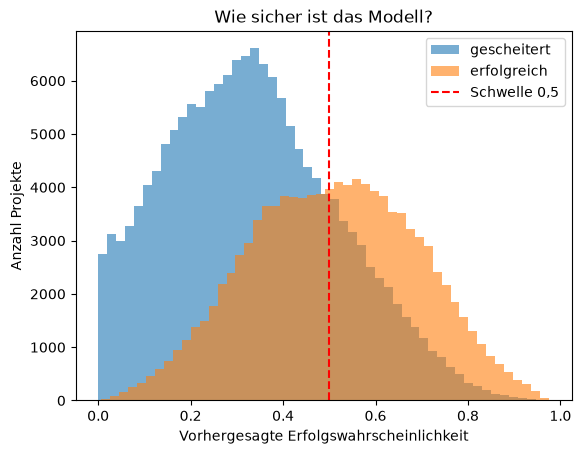

In [37]:
# Visualisierung der vorhergesagten Erfolgswahrscheinlichkeiten für gescheiterte und erfolgreiche Projekte
plt.hist(proba_cv[y_train == 0], bins=50, alpha=0.6, label="gescheitert")
plt.hist(proba_cv[y_train == 1], bins=50, alpha=0.6, label="erfolgreich")
plt.axvline(0.5, color="red", linestyle="--", label="Schwelle 0,5")
plt.xlabel("Vorhergesagte Erfolgswahrscheinlichkeit")
plt.ylabel("Anzahl Projekte")
plt.title("Wie sicher ist das Modell?")
plt.legend()
plt.show()

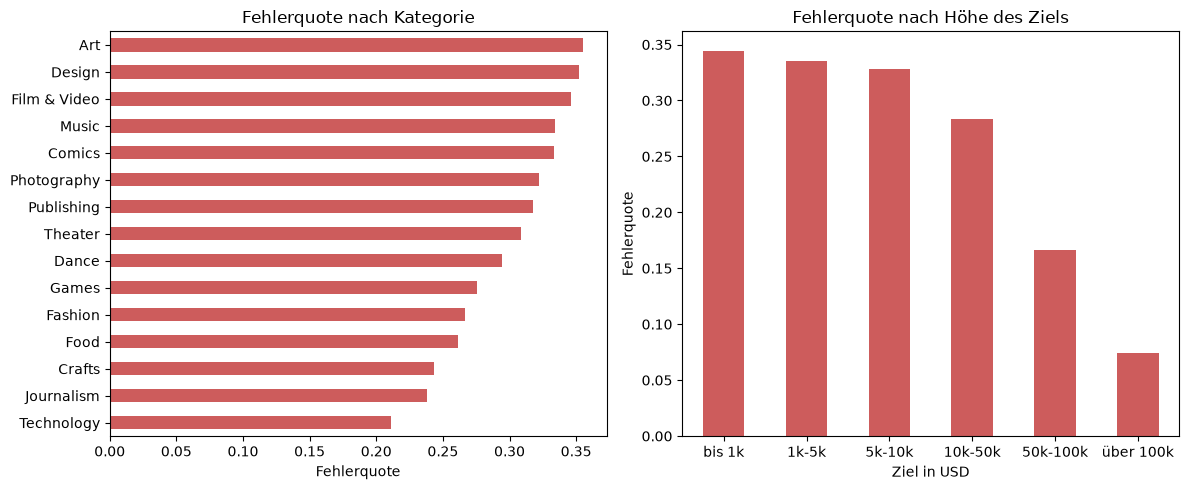

In [38]:
# Visualisierung der Fehlerquote nach Kategorie und Höhe des Finanzierungsziels
errors = X_train_feat.assign(error=(pred_cv != y_train.to_numpy()))
errors["goal_group"] = pd.cut(
    errors["goal_usd"], bins=goal_bins, labels=goal_labels
)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

errors.groupby("main_category")["error"].mean().sort_values().plot(
    kind="barh", ax=axes[0], color="indianred"
)
axes[0].set_xlabel("Fehlerquote")
axes[0].set_ylabel("")
axes[0].set_title("Fehlerquote nach Kategorie")

errors.groupby("goal_group", observed=True)["error"].mean().plot(
    kind="bar", ax=axes[1], color="indianred"
)
axes[1].set_xlabel("Ziel in USD")
axes[1].set_ylabel("Fehlerquote")
axes[1].set_title("Fehlerquote nach Höhe des Ziels")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

## Evaluate the Model

- Testen des Baseline-Modells und des besten Random Forest Modells auf den Testdaten
- Permutation Importance für das beste Random Forest Modell auf den Testdaten
- Speichern des besten Random Forest Modells für die spätere Verwendung

In [39]:
# Testen des Baseline-Modells und des besten Random Forest Modells auf den Testdaten
X_test_feat = add_features(X_test)

final_model = search.best_estimator_
baseline_logreg.fit(X_train_feat, y_train)


def test_scores(model):
    """Berechnet alle Metriken auf den Testdaten."""
    proba = model.predict_proba(X_test_feat)[:, 1]
    pred = (proba >= 0.5).astype(int)
    return {
        "roc_auc": roc_auc_score(y_test, proba),
        "accuracy": accuracy_score(y_test, pred),
        "f1": f1_score(y_test, pred),
        "precision": precision_score(y_test, pred),
        "recall": recall_score(y_test, pred),
    }


test_results = pd.DataFrame({
    "Baseline: LogReg (2 Features)": test_scores(baseline_logreg),
    "Random Forest (getunt)": test_scores(final_model),
}).T.round(3)
test_results

,roc_auc,accuracy,f1,precision,recall
Baseline: LogReg (2 Features),0.671,0.636,0.455,0.575,0.376
Random Forest (getunt),0.749,0.690,0.576,0.644,0.521


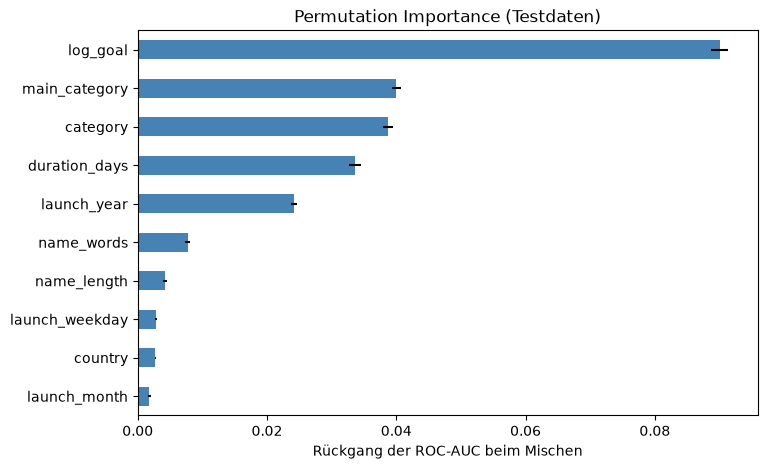

,mean,std
launch_month,0.0018,0.0003
country,0.0027,0.0001
launch_weekday,0.0028,0.0002
name_length,0.0043,0.0003
name_words,0.0077,0.0003
launch_year,0.0242,0.0005
duration_days,0.0336,0.0010
category,0.0387,0.0007
main_category,0.0400,0.0007
log_goal,0.0900,0.0013


In [40]:
# Permutation Importance für das beste Random Forest Modell auf den Testdaten
perm = permutation_importance(
    final_model,
    X_test_feat,
    y_test,
    scoring="roc_auc",
    n_repeats=5,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

importance = pd.DataFrame(
    {"mean": perm.importances_mean, "std": perm.importances_std},
    index=X_test_feat.columns,
).loc[num_features + cat_features].sort_values("mean")

ax = importance["mean"].plot(
    kind="barh", xerr=importance["std"], color="steelblue", figsize=(8, 5)
)
ax.set_xlabel("Rückgang der ROC-AUC beim Mischen")
ax.set_ylabel("")
ax.set_title("Permutation Importance (Testdaten)")
plt.show()

importance.round(4)

In [41]:
# Speichern des besten Random Forest Modells für die spätere Verwendung
joblib.dump(final_model, "models/random_forest_model.joblib", compress=3)

['models/random_forest_model.joblib']

## New Data

- Vorhersage der Erfolgswahrscheinlichkeit für ein neues Projekt
- Vorhersage der Erfolgswahrscheinlichkeit für ein neues Projekt bei verschiedenen Finanzierungszielen

In [42]:
# Vorhersage der Erfolgswahrscheinlichkeit für ein neues Projekt
loaded_model = joblib.load("models/random_forest_model.joblib")

new_project = pd.DataFrame({
    "name": ["Mein erstes Brettspiel"],
    "category": ["Tabletop Games"],
    "main_category": ["Games"],
    "currency": ["EUR"],
    "deadline": [pd.Timestamp("2017-12-01")],
    "launched": [pd.Timestamp("2017-11-01")],
    "country": ["DE"],
    "goal_usd": [10_000.0],
})

new_feat = add_features(new_project)[X_train_feat.columns]
chance = loaded_model.predict_proba(new_feat)[0, 1]
print(f"Erfolgswahrscheinlichkeit: {chance:.0%}")

Erfolgswahrscheinlichkeit: 58%


In [43]:
# Vorhersage der Erfolgswahrscheinlichkeit für ein neues Projekt bei verschiedenen Finanzierungszielen
what_if = pd.concat([new_project] * 4, ignore_index=True)
what_if["goal_usd"] = [2_000.0, 5_000.0, 10_000.0, 25_000.0]

what_if_feat = add_features(what_if)[X_train_feat.columns]
what_if["chance"] = loaded_model.predict_proba(what_if_feat)[:, 1].round(2)
what_if[["goal_usd", "chance"]]

,goal_usd,chance
0,2000.0,0.69
1,5000.0,0.56
2,10000.0,0.58
3,25000.0,0.53
